In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
!gdown 1bwRmKkPwmLKiqOgQ_LnKH0Vsc3mJKmVR

Downloading...
From: https://drive.google.com/uc?id=1bwRmKkPwmLKiqOgQ_LnKH0Vsc3mJKmVR
To: /content/cars24-car-price-cleaned.csv
100% 1.69M/1.69M [00:00<00:00, 90.2MB/s]


In [3]:
df = pd.read_csv("cars24-car-price-cleaned.csv")
df[:5]

,selling_price,year,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
0,1.20,2012.0,120000,19.70,796.0,46.30,11.0,MARUTI,ALTO STD,1,0,0,0,0,1,1,1,0
1,5.50,2016.0,20000,18.90,1197.0,82.00,7.0,HYUNDAI,GRAND I10 ASTA,1,0,0,0,0,1,1,1,0
2,2.15,2010.0,60000,17.00,1197.0,80.00,13.0,HYUNDAI,I20 ASTA,1,0,0,0,0,1,1,1,0
3,2.26,2012.0,37000,20.92,998.0,67.10,11.0,MARUTI,ALTO K10 2010-2014 VXI,1,0,0,0,0,1,1,1,0
4,5.70,2015.0,30000,22.77,1498.0,98.59,8.0,FORD,ECOSPORT 2015-2021 1.5 TDCI TITANIUM BSIV,0,0,1,0,0,0,1,1,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19820 entries, 0 to 19819
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   selling_price     19820 non-null  float64
 1   year              19820 non-null  float64
 2   km_driven         19820 non-null  int64  
 3   mileage           19820 non-null  float64
 4   engine            19820 non-null  float64
 5   max_power         19820 non-null  float64
 6   age               19820 non-null  float64
 7   make              19820 non-null  object 
 8   model             19820 non-null  object 
 9   Individual        19820 non-null  int64  
 10  Trustmark Dealer  19820 non-null  int64  
 11  Diesel            19820 non-null  int64  
 12  Electric          19820 non-null  int64  
 13  LPG               19820 non-null  int64  
 14  Petrol            19820 non-null  int64  
 15  Manual            19820 non-null  int64  
 16  5                 19820 non-null  int64 

In [5]:
df.describe()

,selling_price,year,km_driven,mileage,engine,max_power,age,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
count,19820.000000,19820.000000,1.982000e+04,19820.000000,19820.000000,19820.000000,19820.000000,19820.000000,19820.000000,19820.000000,19820.000000,19820.000000,19820.000000,19820.000000,19820.000000,19820.000000
mean,6.585509,2014.561453,5.815856e+04,19.503402,1475.702381,98.122907,8.438547,0.390666,0.009586,0.492583,0.000404,0.003229,0.487841,0.802674,0.835015,0.152825
std,4.847364,3.196636,5.171563e+04,4.297784,518.571223,44.761727,3.196636,0.487912,0.097442,0.499958,0.020087,0.056734,0.499865,0.397990,0.371176,0.359828
min,0.300000,1992.000000,1.000000e+02,4.000000,0.000000,5.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.410000,2013.000000,3.100000e+04,16.950000,1197.000000,73.900000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
50%,5.200000,2015.000000,5.200000e+04,19.300000,1248.000000,86.800000,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,0.000000
75%,7.850000,2017.000000,7.400000e+04,22.320000,1582.000000,112.000000,10.000000,1.000000,0.000000,1.000000,0.000000,0.000000,1.000000,1.000000,1.000000,0.000000
max,20.902500,2021.000000,3.800000e+06,120.000000,6752.000000,626.000000,31.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


- Max selling price is around 20 lacs but the mean price is 6.5 lacs, it shows the data is righly skewed due to presence of the outliers.

In [8]:
# Exploring the object columns
df.describe(include="O")

,make,model
count,19820,19820
unique,41,3233
top,MARUTI,SWIFT DZIRE VDI
freq,5650,288


### Target Encoding

In [9]:
df.groupby("make")["selling_price"].mean()

,selling_price
make,
AMBASSADOR,1.452500
AUDI,17.177585
BENTLEY,20.902500
BMW,17.349017
CHEVROLET,2.723621
DAEWOO,0.780000
DATSUN,3.205176
DC,11.925000
FERRARI,20.902500


In [11]:
df["make"] = df.groupby("make")["selling_price"].transform('mean')
df["model"] = df.groupby("model")["selling_price"].transform('mean')

In [12]:
df[:5]

,selling_price,year,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
0,1.20,2012.0,120000,19.70,796.0,46.30,11.0,4.684721,1.180000,1,0,0,0,0,1,1,1,0
1,5.50,2016.0,20000,18.90,1197.0,82.00,7.0,5.458819,4.818750,1,0,0,0,0,1,1,1,0
2,2.15,2010.0,60000,17.00,1197.0,80.00,13.0,5.458819,3.394000,1,0,0,0,0,1,1,1,0
3,2.26,2012.0,37000,20.92,998.0,67.10,11.0,4.684721,2.242676,1,0,0,0,0,1,1,1,0
4,5.70,2015.0,30000,22.77,1498.0,98.59,8.0,5.858258,6.777576,0,0,1,0,0,0,1,1,0


### Splitting the Data

In [13]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import  MinMaxScaler, StandardScaler

In [15]:
X= df.drop(columns=["selling_price"])
y = df["selling_price"]

In [16]:
xtrain, xtest, ytrain, ytest = train_test_split(X,y , test_size=0.2, random_state=1)

In [20]:
scaler = StandardScaler()
xtrain = scaler.fit_transform(xtrain)
xtrain

array([[ 1.08056089, -0.74063651,  0.2289024 , ...,  0.49672619,
         0.4466381 , -0.42605178],
       [ 1.08056089, -0.74063651,  0.31846093, ..., -2.01318155,
         0.4466381 , -0.42605178],
       [-0.1701416 ,  0.05260843,  0.2289024 , ...,  0.49672619,
         0.4466381 , -0.42605178],
       ...,
       [ 0.45520964, -0.53288188,  1.30130835, ...,  0.49672619,
         0.4466381 , -0.42605178],
       [-0.79549285, -0.07959906, -1.71153236, ...,  0.49672619,
        -2.23894918,  2.34713255],
       [-1.10816847,  0.22258949,  0.37127749, ...,  0.49672619,
         0.4466381 , -0.42605178]])

In [22]:
xtest= scaler.transform(xtest)
xtest

array([[-1.73351972,  0.22258949, -0.57482797, ...,  0.49672619,
         0.4466381 , -0.42605178],
       [ 0.14253402, -0.00405192,  1.30819747, ...,  0.49672619,
         0.4466381 , -0.42605178],
       [ 0.76788527, -0.15514619,  1.33575394, ...,  0.49672619,
        -2.23894918,  2.34713255],
       ...,
       [ 0.76788527,  0.78919302,  0.08423093, ...,  0.49672619,
         0.4466381 , -0.42605178],
       [ 1.08056089,  0.60032518, -0.81365071, ...,  0.49672619,
        -2.23894918,  2.34713255],
       [-0.79549285,  0.10926879,  0.19675318, ...,  0.49672619,
         0.4466381 , -0.42605178]])

In [24]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()

In [25]:
lr.fit(xtrain, ytrain)

LinearRegression()

In [27]:
df.shape

(19820, 18)

In [29]:
lr.coef_

array([ 0.29052974, -0.08401348, -0.19184559,  0.10742515,  0.07089523,
       -0.29052974,  0.25458235,  4.02218539, -0.06923761, -0.01134001,
        0.06248473,  0.05809759,  0.01548758, -0.08274936, -0.02952704,
       -0.12501692, -0.17694083])

In [30]:
lr.intercept_

np.float64(6.573871058274469)

In [38]:
# feature importance
X.columns[np.argsort(lr.coef_)][::-1]

Index(['model', 'year', 'make', 'engine', 'max_power', 'Diesel', 'Electric',
       'LPG', 'Trustmark Dealer', 'Manual', 'Individual', 'Petrol',
       'km_driven', '5', '>5', 'mileage', 'age'],
      dtype='object')

In [46]:
ypred= lr.predict(xtest)
ypred.shape

(3964,)

In [47]:
ytest = np.array(ytest)

## Evaluation Matrix

### 1. R2 Score

In [48]:
from sklearn.metrics import r2_score

In [49]:
# it calculates the prediction from the already learnt weights and biases.

In [51]:
lr.score(xtrain, ytrain)

0.9447224445496041

In [52]:
lr.score(xtest, ytest)

0.9500669022857815

### 2. MSE and MAE

In [54]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
mse = mean_squared_error(ytest, ypred)

1.1963693603588224

In [56]:
mae= mean_absolute_error(ytest, ypred)
mae

0.7476316658564401

## Checking for the assumptions

### 1. Assumption of Linearity and Homoskedasticity

In [60]:
error = ypred- ytest

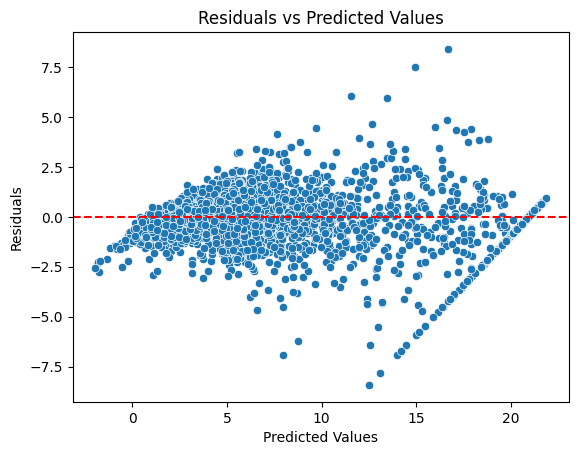

In [63]:
sns.scatterplot(x=ypred, y=error)
plt.axhline(y=0, color='red', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted Values')
plt.show()

In [66]:
# Homoskedasticity assumes the spread of error (Variance) is constant throughout around the predicted y.
# to deal with this, we can take log transformation or box cox transformation.

### 2. Normality

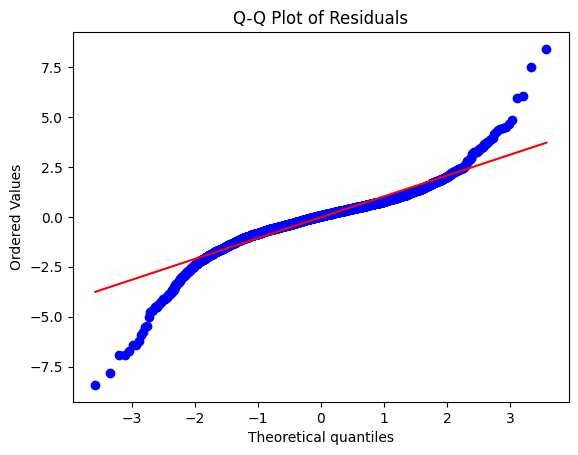

In [64]:
import scipy.stats as stats
import matplotlib.pyplot as plt

stats.probplot(error, dist="norm", plot=plt)
plt.title("Q-Q Plot of Residuals")
plt.show()

In [67]:
# Using shapiro wilk test
# H0 : errors are normally distributed.
# Ha: errors are not normally distributed.

In [68]:
from scipy.stats import shapiro

stat, p_value = shapiro(error)

print("Statistic:", stat)
print("P-value:", p_value)

Statistic: 0.9122452060405198
P-value: 4.42961619419804e-43


In [69]:
H0=  "errors are normally distributed."
Ha =  "errors are not normally distributed."

In [72]:
if p_value >0.05:
  print(H0)
else:
  print(Ha)

errors are not normally distributed.


In [ ]:
# Statistic closer to 1 generally indicates that the sample is more consistent with normality.

our dataset contains approximately 19,820 observations.

With a sample this large, normality tests can detect even relatively small departures from a normal distribution. SciPy also cautions that the Shapiro-Wilk p-value may not be accurate for samples larger than 5,000.

However, your earlier Q-Q plot showed substantial deviations from the reference line, particularly in both tails. That visual evidence supports the conclusion that your residuals are not normally distributed.